# IF25-40305: Sistem Teknologi Multimedia (STM)
## Modul 06 — Music Information Retrieval (MIR): Pitch, Tempo, Kunci, Chord & Fingerprinting

**Institut Teknologi Sumatera (ITERA) — Program Studi Informatika**
*Materi Kuliah & Hands-on Lab Semester Ganjil 2026/2027 · Pertemuan 5*

---

### 🎯 Capaian Pembelajaran Modul 06:
1. Mengonversi **frekuensi ↔ nomor MIDI ↔ nama nada** dan menjelaskan mengapa *pitch* tidak sama dengan puncak spektrum tertinggi (harmonik).
2. Menerapkan **pitch shifting** dan **time stretching** (phase vocoder `librosa`, Rubber Band `pedalboard`), membedakannya dari sekadar *resampling*, dan mengenali artefaknya.
3. Mendeteksi **pitch** dengan autokorelasi, **YIN** (diimplementasikan sendiri), dan **pYIN**, termasuk jebakan *octave error*.
4. Mendeteksi **onset**, mengestimasi **tempo**, dan melakukan **beat tracking**, serta membaca **tempogram** untuk tempo yang berubah.
5. Mengekstraksi **chromagram** untuk memprediksi **kunci lagu (Mayor/Minor)** dengan algoritma **Krumhansl–Schmuckler**.
6. Membangun **chord recognition** berbasis template dan **audio fingerprinting** gaya Shazam dari nol.

> 📎 Slide pendamping: *Pertemuan 5 — Music Information Retrieval (MIR)* (mctm.web.id/stm). Seluruh angka pada slide dihitung dari audio dan kode yang sama dengan notebook ini.

## 1. Import Library & Persiapan Lingkungan

Modul ini memakai pustaka yang sudah ada di `requirements.txt`: **`librosa`** (analisis musik), **`pedalboard`** (time stretch kualitas studio), **`scipy`** (filter & puncak), **`soundfile`**, **`numpy`**, dan **`matplotlib`**.

Audio contoh berada di folder `audio/` dan berlisensi **CC BY 4.0 / domain publik** — lihat `audio/CREDITS.md`:

| Berkas | Isi | Dipakai untuk |
|---|---|---|
| `trumpet_sample.wav` | Solo trumpet monofonik (paket *“in F, 90 bpm”*), 5,3 s | Pitch, shift & stretch |
| `nutcracker_sample.wav` | *Dance of the Sugar Plum Fairy* (E minor), 30 s | Beat, kunci, chord, fingerprint |
| `brahms_sample.wav` | *Hungarian Dance No. 5*, string orchestra, 30 s | Studi kasus deteksi kunci |
| `snare_accelerate.wav` | Snare dengan tempo yang terus naik, 20 s | Tempogram |
| `drums_sample.wav` | Drum & bass, 8 s | Onset & tempo |
| `speech_sample.wav` | Ucapan (LibriSpeech), 4 s | Formant & efek *chipmunk* |
| `music_sample.wav` | *Vibe Ace* (jazz), 10 s | Basis data fingerprint |

In [1]:
import os
import time
import collections
import warnings
import numpy as np
import matplotlib.pyplot as plt
import scipy.ndimage as ndi
import librosa
import librosa.display
import soundfile as sf
from pedalboard import time_stretch as pb_time_stretch
import IPython.display as ipd

# Sembunyikan peringatan internal librosa/numba yang tidak relevan untuk materi
warnings.filterwarnings('ignore', category=UserWarning)
warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', category=RuntimeWarning)

# Konfigurasi visualisasi konsisten
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['figure.dpi'] = 100
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3

# Gambar inline disimpan sebagai JPEG agar ukuran berkas notebook tetap ringan
%config InlineBackend.figure_formats = ['jpeg']
%config InlineBackend.print_figure_kwargs = {'bbox_inches': 'tight', 'pil_kwargs': {'quality': 85}}

AUDIO_DIR = 'audio'
OUTPUT_DIR = 'output'
os.makedirs(OUTPUT_DIR, exist_ok=True)

SR = 22050   # satu sample rate untuk seluruh modul
HOP = 512    # hop STFT default librosa
NOTES = ['C', 'C#', 'D', 'D#', 'E', 'F', 'F#', 'G', 'G#', 'A', 'A#', 'B']

print(f"librosa {librosa.__version__} · numpy {np.__version__}")

librosa 1.0.0 · numpy 2.5.3


In [2]:
def load(name, sr=SR):
    y, _ = librosa.load(os.path.join(AUDIO_DIR, name), sr=sr)
    return y

trumpet    = load('trumpet_sample.wav')
nutcracker = load('nutcracker_sample.wav')
brahms     = load('brahms_sample.wav')
snare      = load('snare_accelerate.wav')
drums      = load('drums_sample.wav')
speech     = load('speech_sample.wav')
music      = load('music_sample.wav')

for name, y in [('trumpet', trumpet), ('nutcracker', nutcracker), ('brahms', brahms),
                ('snare', snare), ('drums', drums), ('speech', speech), ('music', music)]:
    print(f"{name:11s} {len(y)/SR:5.2f} s  ({len(y):7d} sampel)")


def play(y, sr=SR, seconds=None):
    # Pemutar audio inline; `seconds` membatasi durasi agar notebook tetap ringan
    if seconds is not None:
        y = y[:int(seconds * sr)]
    return ipd.Audio(y, rate=sr)


def spec_db(y, n_fft=2048, hop=HOP):
    return librosa.amplitude_to_db(np.abs(librosa.stft(y, n_fft=n_fft, hop_length=hop)), ref=np.max)

trumpet      5.33 s  ( 117601 sampel)
nutcracker  30.00 s  ( 661500 sampel)
brahms      30.00 s  ( 661500 sampel)
snare       20.00 s  ( 441000 sampel)
drums        8.00 s  ( 176400 sampel)
speech       4.00 s  (  88200 sampel)
music       10.00 s  ( 220500 sampel)


## 2. Dasar Musik untuk MIR: Hz, MIDI & Harmonik

Musik memakai **skala logaritmik**. Nomor MIDI $m$ dan frekuensi $f$ dihubungkan oleh:

$$f(m) = 440 \cdot 2^{(m-69)/12} \qquad\Longleftrightarrow\qquad m(f) = 69 + 12\log_2\!\left(\frac{f}{440}\right)$$

- A4 = MIDI 69 = 440 Hz.
- Satu **semitone** = rasio $2^{1/12} \approx 1{,}0595$ (naik ~5,9 %), dan dibagi lagi menjadi **100 cents**.
- Satu **oktaf** = 12 semitone = frekuensi ×2.

Kita tulis konversinya secara manual, lalu cocokkan dengan fungsi `librosa`.

In [3]:
def hz_to_midi(f):
    return 69 + 12 * np.log2(np.asarray(f, dtype=float) / 440.0)

def midi_to_hz(m):
    return 440.0 * 2 ** ((np.asarray(m, dtype=float) - 69) / 12)

def describe(f):
    m = hz_to_midi(f)
    nearest = int(np.round(m))
    cents = 100 * (m - nearest)
    return f"{f:8.2f} Hz → MIDI {m:6.2f} → {librosa.midi_to_note(nearest, unicode=False):4s} ({cents:+5.1f} cents)"

for f in [440, 523.25, 330, 346.6, 110, 116.54]:
    print(describe(f))

# Validasi dengan librosa
assert np.isclose(hz_to_midi(523.25), librosa.hz_to_midi(523.25))
print("\nRasio 1 semitone :", 2 ** (1 / 12))
print("Rasio +7 semitone:", 2 ** (7 / 12), "(≈ 3/2, interval kuint)")
print("Selisih A2→A#2   :", midi_to_hz(46) - midi_to_hz(45), "Hz")
print("Selisih A6→A#6   :", midi_to_hz(94) - midi_to_hz(93), "Hz  ← sama-sama 1 semitone")

  440.00 Hz → MIDI  69.00 → A4   ( +0.0 cents)
  523.25 Hz → MIDI  72.00 → C5   ( -0.0 cents)
  330.00 Hz → MIDI  64.02 → E4   ( +2.0 cents)
  346.60 Hz → MIDI  64.87 → F4   (-13.1 cents)
  110.00 Hz → MIDI  45.00 → A2   ( +0.0 cents)
  116.54 Hz → MIDI  46.00 → A#2  ( -0.0 cents)

Rasio 1 semitone : 1.0594630943592953
Rasio +7 semitone: 1.4983070768766815 (≈ 3/2, interval kuint)
Selisih A2→A#2   : 6.540940379522482 Hz
Selisih A6→A#6   : 104.65504607235971 Hz  ← sama-sama 1 semitone


### 2.1 Pitch ≠ puncak spektrum tertinggi

Satu nada instrumen terdiri dari frekuensi dasar $f_0$ dan **harmonik** di $k \cdot f_0$. Kita ambil satu frame dari nada F4 trumpet (frame paling keras yang ber-*pitch* F4 menurut pYIN), lalu bandingkan:
- $f_0$ dari periode gelombang, dan
- puncak FFT tertinggi.

f0 (pYIN)            :   346.6 Hz → F4
Puncak FFT tertinggi :  1045.7 Hz → C6  (≈ 3.02 × f0)


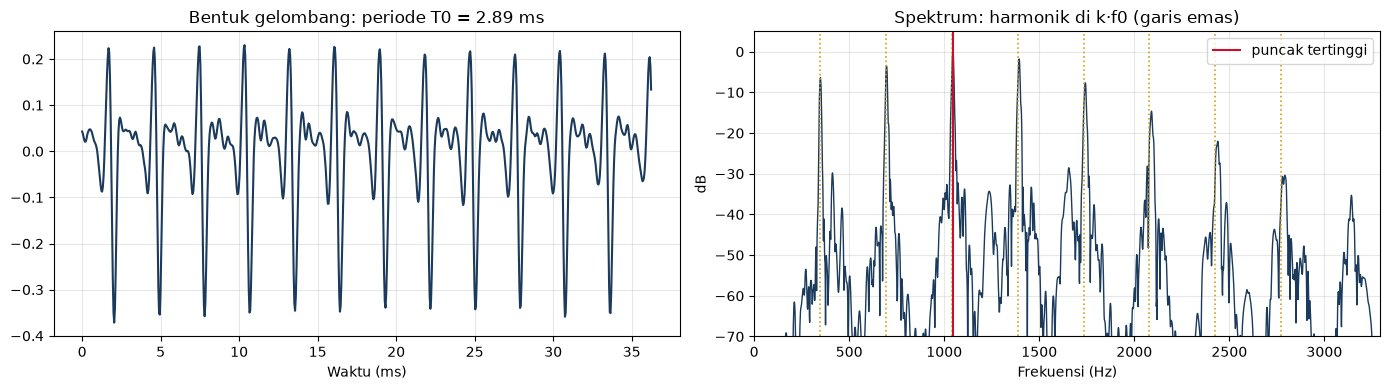

In [4]:
f0_tr, vf_tr, vp_tr = librosa.pyin(trumpet, fmin=150, fmax=1000, sr=SR, hop_length=HOP)
midi_tr = np.round(librosa.hz_to_midi(f0_tr))
rms_tr = librosa.feature.rms(y=trumpet, hop_length=HOP)[0]

idx = np.where(vf_tr & (midi_tr == 65))[0]          # frame bersuara bernada F4
i0 = idx[np.argmax(rms_tr[idx])]
s0 = i0 * HOP
seg = trumpet[s0:s0 + 4096] * np.hanning(4096)

S = np.abs(np.fft.rfft(seg, 16384))
freqs = np.fft.rfftfreq(16384, 1 / SR)
peak_hz = freqs[np.argmax(S)]
f0_ref = f0_tr[i0]

print(f"f0 (pYIN)            : {f0_ref:7.1f} Hz → {librosa.hz_to_note(f0_ref)}")
print(f"Puncak FFT tertinggi : {peak_hz:7.1f} Hz → {librosa.hz_to_note(peak_hz)}  (≈ {peak_hz / f0_ref:.2f} × f0)")

fig, axs = plt.subplots(1, 2, figsize=(14, 4))
t_ms = np.arange(800) / SR * 1000
axs[0].plot(t_ms, trumpet[s0:s0 + 800], color='#1B3A5C')
axs[0].set_title(f'Bentuk gelombang: periode T0 = {1000 / f0_ref:.2f} ms')
axs[0].set_xlabel('Waktu (ms)')
Sdb = 20 * np.log10(S / S.max() + 1e-6)
axs[1].plot(freqs, Sdb, color='#1B3A5C', lw=1)
for k in range(1, 9):
    axs[1].axvline(k * f0_ref, color='#D4A017', ls=':', lw=1.2)
axs[1].axvline(peak_hz, color='#C8102E', lw=1.5, label='puncak tertinggi')
axs[1].set_xlim(0, 9.5 * f0_ref); axs[1].set_ylim(-70, 5)
axs[1].set_title('Spektrum: harmonik di k·f0 (garis emas)')
axs[1].set_xlabel('Frekuensi (Hz)'); axs[1].set_ylabel('dB'); axs[1].legend()
plt.tight_layout(); plt.show()

> 💡 **Pengamatan:** puncak terkuat berada di salah satu harmonik atas, bukan di $f_0$. Detektor pitch yang hanya mengambil `argmax` FFT akan meleset **satu oktaf atau lebih**. Inilah alasan kita memakai metode berbasis **periodisitas** (Bagian 4).

## 3. Pitch Shifting & Time Stretching

Ada tiga operasi yang sering tertukar:

| Operasi | Durasi | Pitch | Cara |
|---|---|---|---|
| **Resample / putar lebih cepat** | berubah | berubah | ubah laju sampel (seperti memutar kaset lebih cepat) |
| **Time stretch** | berubah | **tetap** | phase vocoder: frame STFT dirapatkan/direnggangkan |
| **Pitch shift** | **tetap** | berubah | time stretch + resample |

Pertama kita bandingkan ketiganya pada trumpet dengan faktor 1,5 (= +7,02 semitone).

In [5]:
def dominant_note(y):
    f0, vf, _ = librosa.pyin(y, fmin=150, fmax=1500, sr=SR)
    m = np.round(librosa.hz_to_midi(f0[vf])).astype(int)
    return librosa.midi_to_note(collections.Counter(m).most_common(1)[0][0], unicode=False)

speed_up = librosa.resample(trumpet, orig_sr=SR, target_sr=int(SR / 1.5))  # diputar di SR → 1,5× cepat
stretch  = librosa.effects.time_stretch(trumpet, rate=1.5)
shift7   = librosa.effects.pitch_shift(trumpet, sr=SR, n_steps=7)

versions = {'Asli': trumpet, 'Resample 1,5×': speed_up,
            'Time stretch rate=1,5': stretch, 'Pitch shift +7': shift7}
for name, y in versions.items():
    print(f"{name:22s} durasi {len(y)/SR:5.2f} s   nada dominan {dominant_note(y)}")
print("\n12·log2(1,5) =", round(12 * np.log2(1.5), 2), "semitone")

Asli                   durasi  5.33 s   nada dominan F4
Resample 1,5×          durasi  3.56 s   nada dominan C5
Time stretch rate=1,5  durasi  3.56 s   nada dominan F4
Pitch shift +7         durasi  5.33 s   nada dominan C5

12·log2(1,5) = 7.02 semitone


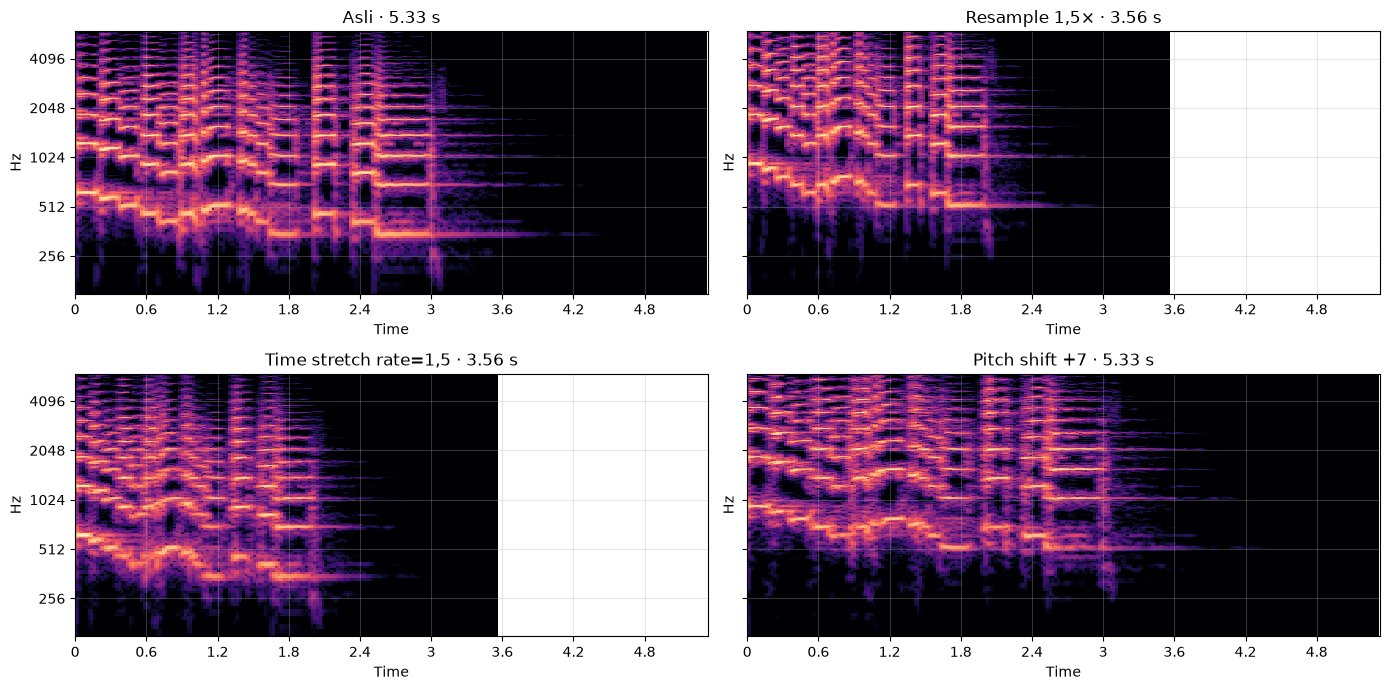

In [6]:
fig, axs = plt.subplots(2, 2, figsize=(14, 7), sharey=True)
for ax, (name, y) in zip(axs.ravel(), versions.items()):
    librosa.display.specshow(spec_db(y), sr=SR, hop_length=HOP, x_axis='time', y_axis='log', ax=ax, cmap='magma')
    ax.set_xlim(0, len(trumpet) / SR); ax.set_ylim(150, 6000)
    ax.set_title(f"{name} · {len(y)/SR:.2f} s")
plt.tight_layout(); plt.show()

Dengarkan keempat versi. Perhatikan bahwa **resample** mengubah tempo *dan* nada sekaligus, sedangkan dua versi lainnya hanya mengubah salah satunya.

In [7]:
for name, y in versions.items():
    print(name)
    ipd.display(play(y))

Asli


Resample 1,5×


Time stretch rate=1,5


Pitch shift +7


### 3.1 Membongkar `pitch_shift`: stretch + resample

`librosa.effects.pitch_shift` dengan `n_steps = n` bekerja dalam dua langkah:
1. **Time stretch** dengan `rate = 2^(-n/12)` → durasi menjadi $2^{n/12}$ kali lebih panjang, pitch tetap.
2. **Resample** dengan faktor $2^{n/12}$ → durasi kembali seperti semula, semua frekuensi dikali $2^{n/12}$.

Kita rakit ulang secara manual dan bandingkan hasilnya.

In [8]:
n = 7
rate = 2 ** (-n / 12)
step1 = librosa.effects.time_stretch(trumpet, rate=rate)
step2 = librosa.resample(step1, orig_sr=SR / rate, target_sr=SR, res_type='soxr_hq')
step2 = librosa.util.fix_length(step2, size=len(trumpet))

print(f"rate stretch      : {rate:.4f}")
print(f"setelah stretch   : {len(step1)/SR:.2f} s")
print(f"setelah resample  : {len(step2)/SR:.2f} s")
corr = np.corrcoef(step2, shift7)[0, 1]
print(f"korelasi dengan librosa.effects.pitch_shift: {corr:.4f}")

rate stretch      : 0.6674
setelah stretch   : 7.99 s
setelah resample  : 5.33 s
korelasi dengan librosa.effects.pitch_shift: 1.0000


### 3.2 `pedalboard.time_stretch`: kualitas studio

`pedalboard` membungkus pustaka **Rubber Band**, yang menangani transien secara khusus dan dapat **mempertahankan formant**. Satu panggilan bisa mengubah tempo dan pitch sekaligus. Perhatikan:
- `stretch_factor > 1` berarti **lebih cepat** (sama seperti `rate` di librosa);
- input harus `float32`, dan output berbentuk `(channel, sampel)`.

In [9]:
pb_fast = pb_time_stretch(trumpet.astype(np.float32), SR, stretch_factor=1.5)[0]
pb_shift = pb_time_stretch(trumpet.astype(np.float32), SR, stretch_factor=1.0,
                           pitch_shift_in_semitones=7)[0]
print(f"pedalboard stretch 1,5 : {len(pb_fast)/SR:.2f} s, nada dominan {dominant_note(pb_fast)}")
print(f"pedalboard shift +7    : {len(pb_shift)/SR:.2f} s, nada dominan {dominant_note(pb_shift)}")

sf.write(os.path.join(OUTPUT_DIR, 'trumpet_up7_librosa.wav'), shift7, SR)
sf.write(os.path.join(OUTPUT_DIR, 'trumpet_up7_pedalboard.wav'), pb_shift, SR)
print("Tersimpan di output/: trumpet_up7_librosa.wav & trumpet_up7_pedalboard.wav — bandingkan dengan headphone.")

pedalboard stretch 1,5 : 3.56 s, nada dominan F4


pedalboard shift +7    : 5.33 s, nada dominan C5
Tersimpan di output/: trumpet_up7_librosa.wav & trumpet_up7_pedalboard.wav — bandingkan dengan headphone.


### 3.3 Artefak: transien mengabur & formant bergeser

1. **Transient smearing.** Phase vocoder memproses frame berukuran 2048 sampel (~93 ms). Serangan snare yang tajam ikut “tersebar” ke seluruh frame, bahkan muncul sedikit **sebelum** pukulan (*pre-echo*).
2. **Formant shift.** Pitch shift biasa menggeser *seluruh* spektrum, termasuk **formant** (resonansi rongga mulut). Ucapan terdengar seperti tupai (*chipmunk*). Opsi `preserve_formants=True` di `pedalboard` mempertahankannya.

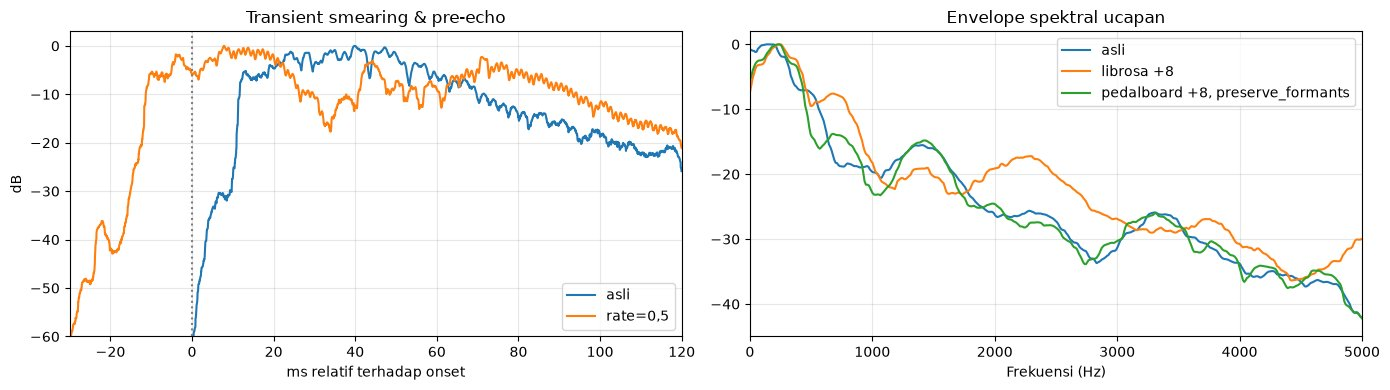

Asli → librosa +8 → pedalboard +8 (formant dipertahankan):


In [10]:
# (1) Envelope pukulan snare pertama: asli vs time stretch rate=0,5 (waktu dinormalisasi)
on = librosa.onset.onset_detect(y=snare, sr=SR, units='samples', backtrack=True)[0]
slow = librosa.effects.time_stretch(snare, rate=0.5)

def env_db(x, n):
    e = np.sqrt(np.convolve(x ** 2, np.ones(n) / n, mode='same'))
    return 20 * np.log10(e / e.max() + 1e-5)

pre, post = int(0.03 * SR), int(0.12 * SR)
a = snare[on - pre:on + post]
b = slow[2 * on - 2 * pre:2 * on + 2 * post]

# (2) Envelope spektral rata-rata ucapan: asli vs pitch shift +8
up8 = librosa.effects.pitch_shift(speech, sr=SR, n_steps=8)
up8_pf = pb_time_stretch(speech.astype(np.float32), SR, pitch_shift_in_semitones=8,
                         preserve_formants=True)[0]

def spectral_env(y):
    p = (np.abs(librosa.stft(y, n_fft=2048)) ** 2).mean(axis=1)
    p = ndi.uniform_filter1d(p, 25)
    return 10 * np.log10(p / p.max() + 1e-9)

f_axis = librosa.fft_frequencies(sr=SR, n_fft=2048)
fig, axs = plt.subplots(1, 2, figsize=(14, 4))
axs[0].plot((np.arange(len(a)) - pre) / SR * 1000, env_db(a, 44), label='asli')
axs[0].plot((np.arange(len(b)) - 2 * pre) / SR * 500, env_db(b, 88), label='rate=0,5')
axs[0].axvline(0, color='gray', ls=':'); axs[0].set_xlim(-30, 120); axs[0].set_ylim(-60, 3)
axs[0].set_xlabel('ms relatif terhadap onset'); axs[0].set_ylabel('dB'); axs[0].legend()
axs[0].set_title('Transient smearing & pre-echo')
for y, lab in [(speech, 'asli'), (up8, 'librosa +8'), (up8_pf, 'pedalboard +8, preserve_formants')]:
    axs[1].plot(f_axis, spectral_env(y), label=lab)
axs[1].set_xlim(0, 5000); axs[1].set_ylim(-45, 2)
axs[1].set_xlabel('Frekuensi (Hz)'); axs[1].set_title('Envelope spektral ucapan'); axs[1].legend()
plt.tight_layout(); plt.show()

print("Asli → librosa +8 → pedalboard +8 (formant dipertahankan):")
for y in (speech, up8, up8_pf):
    ipd.display(play(y))

## 4. Deteksi Pitch: ACF → YIN → pYIN

### 4.1 Autokorelasi (ACF)

Sinyal periodik mirip dengan dirinya sendiri yang digeser satu periode:

$$r(\tau) = \sum_n x[n]\,x[n+\tau]$$

Puncak pertama setelah $\tau = 0$ memberi periode $T_0$ (dalam sampel), sehingga $f_0 = \text{sr} / \tau$. Kita pakai frame F4 yang sama seperti di Bagian 2.

In [11]:
W = 1024
x = trumpet[s0:s0 + 2 * W]
lags = np.arange(1, 400)
acf = np.array([np.sum(x[:W] * x[l:l + W]) for l in lags])
acf = acf / acf.max()

min_lag = int(SR / 1000)                 # abaikan f0 > 1000 Hz
best = min_lag + np.argmax(acf[min_lag:])
print(f"Puncak ACF: lag {lags[best]} sampel → f0 = {SR}/{lags[best]} = {SR / lags[best]:.1f} Hz "
      f"({librosa.hz_to_note(SR / lags[best])})")

# Jebakan oktaf: puncak di 2× lag hampir sama tinggi
k2 = 2 * lags[best]
print(f"ACF di lag {lags[best]}: {acf[best]:.3f}  |  di lag {k2}: {acf[k2 - 1]:.3f} "
      f"→ jika menang, f0 = {SR / k2:.1f} Hz (satu oktaf lebih rendah)")

Puncak ACF: lag 63 sampel → f0 = 22050/63 = 350.0 Hz (F4)
ACF di lag 63: 1.000  |  di lag 126: 0.976 → jika menang, f0 = 175.0 Hz (satu oktaf lebih rendah)


### 4.2 YIN — diimplementasikan dari nol

YIN (de Cheveigné & Kawahara, 2002) memperbaiki ACF dalam tiga langkah:
1. **Difference function** $d(\tau) = \sum_n \big(x[n] - x[n+\tau]\big)^2$ — bernilai kecil saat $\tau$ = periode.
2. **Cumulative mean normalized difference (CMND)** $d'(\tau) = d(\tau) \Big/ \frac{1}{\tau}\sum_{j=1}^{\tau} d(j)$, dengan $d'(0) = 1$, agar tidak memihak $\tau$ kecil.
3. Ambil $\tau$ **pertama** dengan $d'(\tau)$ di bawah ambang (mis. 0,1), lalu turuni lembah lokalnya. Mengambil yang **pertama** (bukan minimum global) inilah yang mencegah *octave error*.

YIN manual  : 350.0 Hz
librosa.yin : 348.8 Hz (median frame)
pYIN        : 346.6 Hz


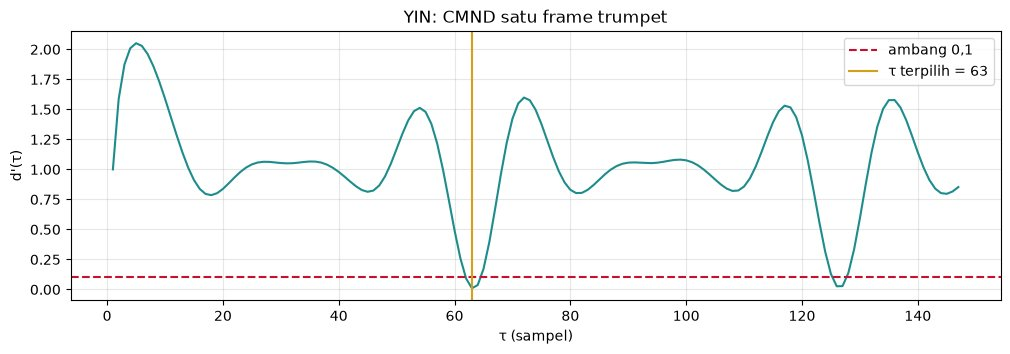

In [12]:
def yin_frame(x, sr, W=1024, fmin=150, fmax=1000, threshold=0.1):
    tau_min, tau_max = int(sr / fmax), int(sr / fmin)
    taus = np.arange(1, tau_max + 1)
    d = np.array([np.sum((x[:W] - x[t:t + W]) ** 2) for t in taus])
    cmnd = d * taus / np.cumsum(d)
    cand = np.where(cmnd[tau_min - 1:] < threshold)[0]
    if len(cand) == 0:
        return np.nan, cmnd                      # tidak bersuara / tidak yakin
    j = cand[0] + tau_min - 1
    while j + 1 < len(cmnd) and cmnd[j + 1] < cmnd[j]:
        j += 1                                   # turuni lembah sampai minimum lokal
    return sr / taus[j], cmnd

f0_yin, cmnd = yin_frame(trumpet[s0:s0 + 2 * 1024 + 2048], SR)
f0_lib = librosa.yin(trumpet[s0:s0 + 4096], fmin=150, fmax=1000, sr=SR, frame_length=2048)
print(f"YIN manual  : {f0_yin:.1f} Hz")
print(f"librosa.yin : {np.median(f0_lib):.1f} Hz (median frame)")
print(f"pYIN        : {f0_ref:.1f} Hz")

plt.figure(figsize=(12, 3.5))
plt.plot(np.arange(1, len(cmnd) + 1), cmnd, color='#1E8C8C')
plt.axhline(0.1, color='#C8102E', ls='--', label='ambang 0,1')
plt.axvline(SR / f0_yin, color='#D4A017', label=f'τ terpilih = {SR / f0_yin:.0f}')
plt.xlabel('τ (sampel)'); plt.ylabel("d'(τ)"); plt.title('YIN: CMND satu frame trumpet'); plt.legend()
plt.show()

### 4.3 pYIN: kontur nada sepanjang waktu

**pYIN** (Mauch & Dixon, 2014) menjalankan YIN dengan **banyak ambang** sekaligus, lalu memilih jalur paling mungkin dengan **HMM**. Hasilnya tiga array per frame:
- `f0` — frekuensi dasar (Hz), `NaN` bila tidak bersuara,
- `voiced_flag` — bersuara atau tidak,
- `voiced_prob` — probabilitas bersuara.

Rentang `fmin`/`fmax` sebaiknya disesuaikan dengan instrumen: terlalu lebar membuat proses lebih lambat dan lebih rawan salah.

pYIN selesai dalam 0.07 s · frame bersuara 83%


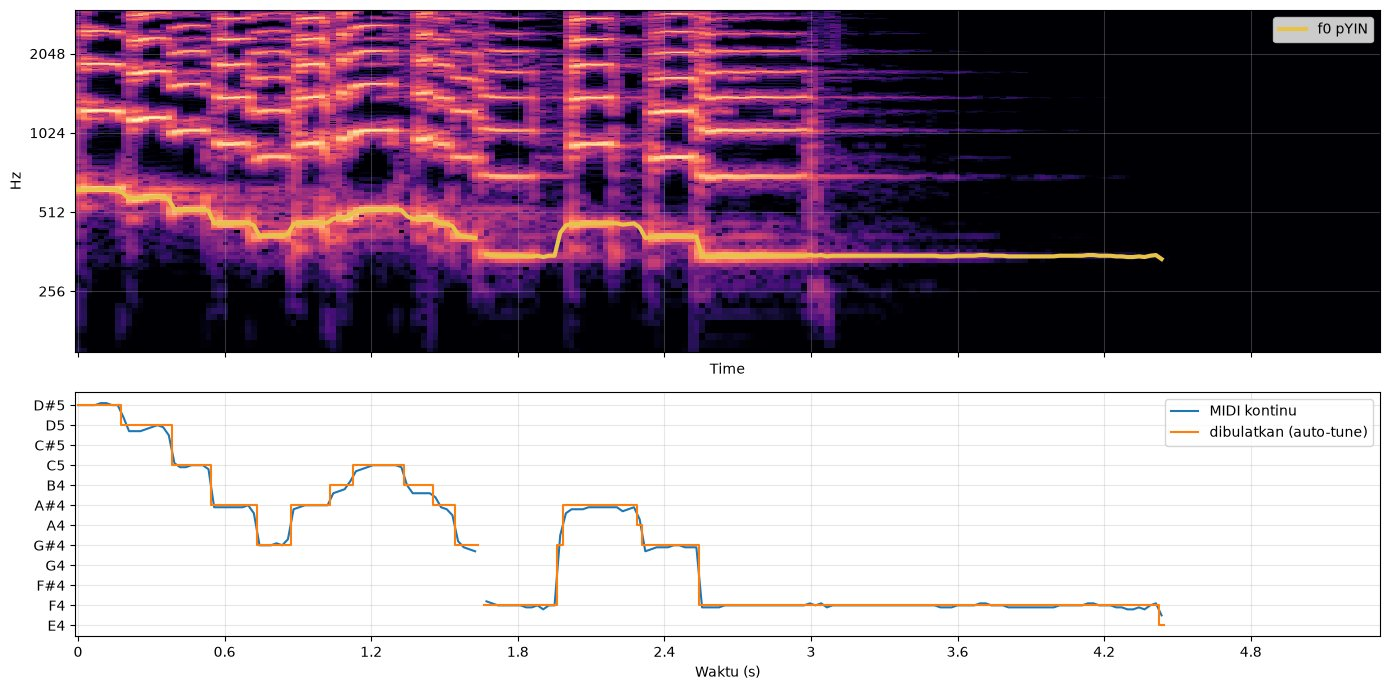

In [13]:
t0 = time.perf_counter()
f0, voiced, vprob = librosa.pyin(trumpet, sr=SR, fmin=librosa.note_to_hz('C3'),
                                 fmax=librosa.note_to_hz('C6'), hop_length=HOP)
print(f"pYIN selesai dalam {time.perf_counter() - t0:.2f} s · frame bersuara {voiced.mean() * 100:.0f}%")

t = librosa.times_like(f0, sr=SR, hop_length=HOP)
midi = librosa.hz_to_midi(f0)

fig, axs = plt.subplots(2, 1, figsize=(14, 7), sharex=True, gridspec_kw={'height_ratios': [1.4, 1]})
librosa.display.specshow(spec_db(trumpet), sr=SR, hop_length=HOP, x_axis='time', y_axis='log', ax=axs[0], cmap='magma')
axs[0].plot(t, f0, color='#E8C34A', lw=3, label='f0 pYIN')
axs[0].set_ylim(150, 3000); axs[0].legend(loc='upper right')
axs[1].plot(t, midi, label='MIDI kontinu')
axs[1].step(t, np.round(midi), where='mid', label='dibulatkan (auto-tune)')
ticks = np.arange(64, 76)
axs[1].set_yticks(ticks); axs[1].set_yticklabels([librosa.midi_to_note(k, unicode=False) for k in ticks])
axs[1].legend(loc='upper right'); axs[1].set_xlabel('Waktu (s)')
plt.tight_layout(); plt.show()

Dari kontur frame-per-frame, kita bisa **menyegmentasi nada**: gabungkan frame berurutan dengan nada bulat yang sama, lalu buang segmen yang terlalu pendek. Hasilnya adalah “transkripsi” sederhana dari melodi trumpet.

In [14]:
notes_r = np.where(voiced, np.round(midi), -1).astype(int)
segments = []
start = 0
for i in range(1, len(notes_r) + 1):
    if i == len(notes_r) or notes_r[i] != notes_r[start]:
        if notes_r[start] > 0 and (i - start) * HOP / SR >= 0.08:          # minimal 80 ms
            cents = 100 * np.nanmedian(midi[start:i] - notes_r[start])
            segments.append((t[start], (i - start) * HOP / SR,
                             librosa.midi_to_note(notes_r[start], unicode=False), cents))
        start = i

print(f"{'mulai':>6s} {'durasi':>7s}  nada  intonasi")
for st, du, nm, c in segments:
    print(f"{st:6.2f} {du:7.2f}  {nm:4s}  {c:+5.0f} cents")

cnt = collections.Counter(librosa.midi_to_note(notes_r[notes_r > 0], unicode=False))
print("\nNada terbanyak (jumlah frame):", cnt.most_common(5))

 mulai  durasi  nada  intonasi
  0.00    0.19  D#5      +0 cents
  0.19    0.21  D5      -20 cents
  0.39    0.16  C5       +0 cents
  0.56    0.19  A#4     -10 cents
  0.74    0.14  G#4      +0 cents
  0.88    0.16  A#4      -0 cents
  1.04    0.09  B4      -25 cents
  1.14    0.21  C5       +0 cents
  1.35    0.12  B4      -40 cents
  1.46    0.09  A#4     -15 cents
  1.56    0.09  G#4     -15 cents
  1.67    0.30  F4       +0 cents
  2.00    0.30  A#4     -10 cents
  2.32    0.23  G#4     -10 cents
  2.55    1.88  F4       +0 cents

Nada terbanyak (jumlah frame): [(np.str_('F4'), 94), (np.str_('A#4'), 32), (np.str_('G#4'), 21), (np.str_('C5'), 16), (np.str_('D5'), 9)]


> 💡 **Pengamatan:** nada yang paling lama dimainkan adalah **F4** — konsisten dengan keterangan paket sampel *“in F”*. Kolom *intonasi* menunjukkan seberapa *flat*/*sharp* pemain trumpet terhadap nada yang tepat; inilah informasi yang “diperbaiki” oleh auto-tune.

## 5. Onset, Tempo & Beat

| Istilah | Arti |
|---|---|
| **Onset** | awal peristiwa bunyi (pukulan, petikan) |
| **Beat** | denyut yang diketukkan pendengar — tidak selalu ada onset di sana |
| **Tempo** | laju beat dalam BPM = 60 / interval beat (detik) |

### 5.1 Onset strength = spectral flux

$$\text{SF}[m] = \sum_k \max\big(0,\ |X_m[k]| - |X_{m-1}[k]|\big)$$

Hanya **kenaikan** energi yang dihitung. Kita hitung secara manual pada mel-spektrogram (dB), lalu bandingkan dengan `librosa.onset.onset_strength`.

korelasi spectral flux manual vs librosa: 1.000
16 onset dalam 4 s: [0.07 0.49 0.6  0.88 0.93 1.37 1.58 1.79 2.04 2.21 2.44 2.67 2.97 3.13
 3.34 3.55]


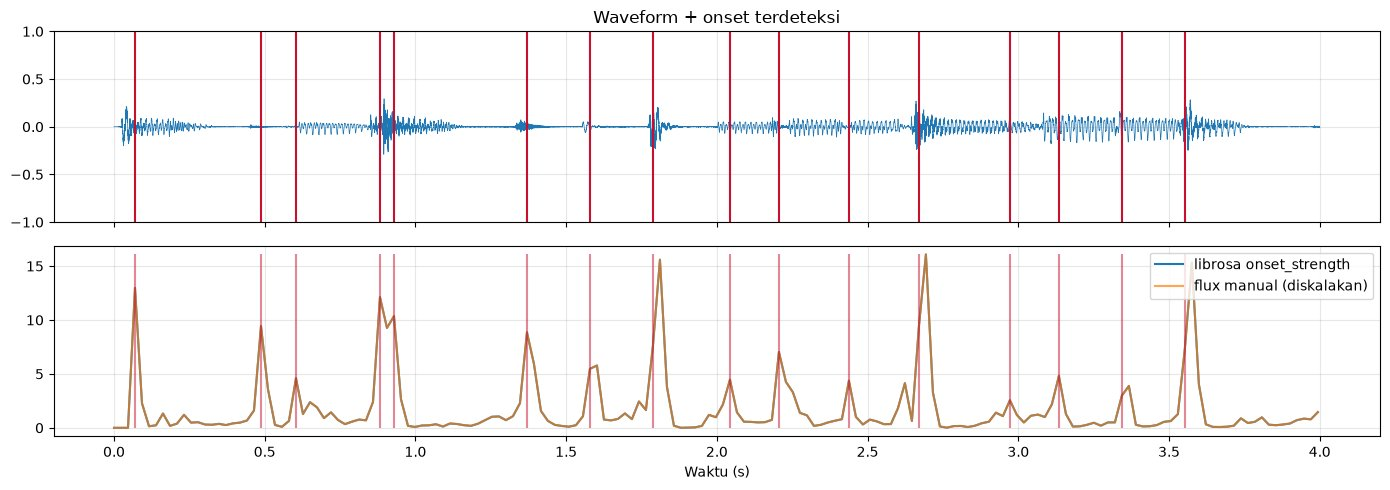

In [15]:
y4 = drums[:4 * SR]
M = librosa.power_to_db(librosa.feature.melspectrogram(y=y4, sr=SR, hop_length=HOP, n_mels=128), ref=np.max)
flux = np.maximum(0, np.diff(M, axis=1)).mean(axis=0)
# librosa menggeser envelope 1 + n_fft/(2·hop) = 3 frame agar puncak sejajar dengan waktu onset
shift = 1 + 2048 // (2 * HOP)
flux = np.pad(flux, (shift, 0))[:M.shape[1]]

oenv = librosa.onset.onset_strength(y=y4, sr=SR, hop_length=HOP)
n = min(len(flux), len(oenv))
print(f"korelasi spectral flux manual vs librosa: {np.corrcoef(flux[:n], oenv[:n])[0, 1]:.3f}")

onsets = librosa.onset.onset_detect(onset_envelope=oenv, sr=SR, hop_length=HOP, units='time')
print(f"{len(onsets)} onset dalam 4 s:", np.round(onsets, 2))

t_o = librosa.times_like(oenv, sr=SR, hop_length=HOP)
fig, axs = plt.subplots(2, 1, figsize=(14, 5), sharex=True)
axs[0].plot(np.arange(len(y4)) / SR, y4, lw=0.5)
axs[0].vlines(onsets, -1, 1, color='#C8102E')
axs[0].set_ylim(-1, 1); axs[0].set_title('Waveform + onset terdeteksi')
axs[1].plot(t_o, oenv, label='librosa onset_strength')
axs[1].plot(t_o[:n], flux[:n] / flux.max() * oenv.max(), alpha=0.7, label='flux manual (diskalakan)')
axs[1].vlines(onsets, 0, oenv.max(), color='#C8102E', alpha=0.5)
axs[1].legend(); axs[1].set_xlabel('Waktu (s)')
plt.tight_layout(); plt.show()

### 5.2 Estimasi tempo & ambiguitas oktaf

Tempo dicari dari **autokorelasi onset envelope**: lag (dalam frame) dikonversi ke BPM dengan

$$\text{BPM} = \frac{60 \cdot \text{sr}}{\text{hop} \cdot \text{lag}}$$

`librosa.feature.tempo` mengalikan skor autokorelasi dengan **prior log-normal** di sekitar `start_bpm` (default 120). Karena itu hasilnya dapat berubah hanya dengan menggeser prior.

Puncak ACF tertinggi : lag 38 → 68.0 BPM
start_bpm= 60 → tempo   68.0 BPM
start_bpm=120 → tempo  136.0 BPM
start_bpm=200 → tempo  136.0 BPM

Resolusi lag: lag 19 → 136.0 BPM; lag 20 → 129.2 BPM


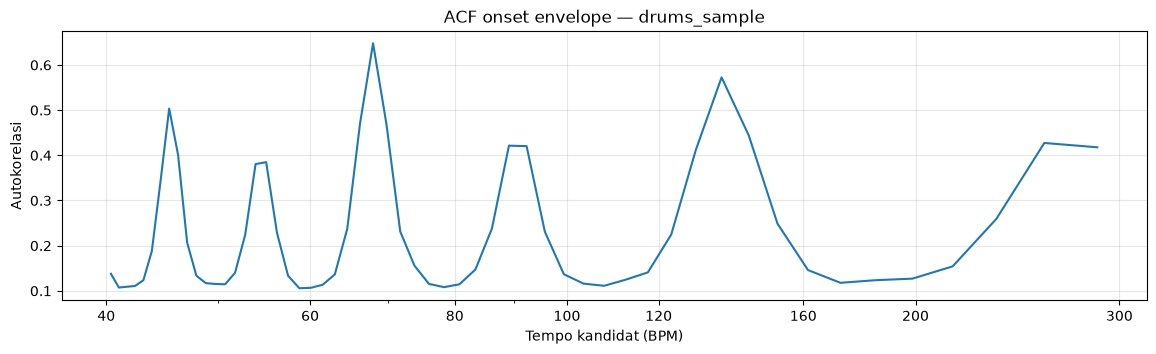

In [16]:
oenv_d = librosa.onset.onset_strength(y=drums, sr=SR, hop_length=HOP)
ac = librosa.autocorrelate(oenv_d, max_size=4 * SR // HOP)
ac = ac / ac.max()
lag = np.arange(1, len(ac))
bpm = 60 * SR / HOP / lag

sel = (bpm >= 40) & (bpm <= 300)
top = lag[sel][np.argmax(ac[1:][sel])]
print(f"Puncak ACF tertinggi : lag {top} → {60 * SR / HOP / top:.1f} BPM")
for sb in (60, 120, 200):
    tempo = librosa.feature.tempo(onset_envelope=oenv_d, sr=SR, hop_length=HOP, start_bpm=sb)[0]
    print(f"start_bpm={sb:3d} → tempo {tempo:6.1f} BPM")
print("\nResolusi lag: lag 19 →", round(60 * SR / HOP / 19, 1), "BPM; lag 20 →", round(60 * SR / HOP / 20, 1), "BPM")

plt.figure(figsize=(14, 3.5))
plt.semilogx(bpm[sel], ac[1:][sel])
plt.xticks([40, 60, 80, 100, 120, 160, 200, 300], ['40', '60', '80', '100', '120', '160', '200', '300'])
plt.xlabel('Tempo kandidat (BPM)'); plt.ylabel('Autokorelasi'); plt.title('ACF onset envelope — drums_sample')
plt.show()

> 💡 **Pengamatan:** puncak tertinggi berada di **68 BPM**, tetapi dengan prior default librosa memilih **136 BPM** (kelipatan 2). Keduanya adalah tafsiran **level metrik** yang berbeda dari ritme yang sama. Laporkan juga kandidat kedua bila aplikasi Anda sensitif terhadap hal ini (misalnya rekomendasi lagu untuk lari).

### 5.3 Beat tracking (dynamic programming)

`librosa.beat.beat_track` (Ellis, 2007) mencari deret beat $t_i$ yang memaksimalkan

$$C(\{t_i\}) = \sum_i O(t_i) - \alpha \sum_i \Big(\log\frac{t_i - t_{i-1}}{\tau_p}\Big)^2$$

yaitu beat yang jatuh di onset kuat **dan** berjarak hampir sama dengan periode tempo $\tau_p$. Parameter $\alpha$ adalah `tightness`.

Tempo estimasi  : 107.7 BPM
Jumlah beat     : 20 dalam 12 s
Beat pertama    : frame 51 → 51 × 512 / 22050 = 1.184 s
4 beat pertama  : [1.184 1.718 2.322 2.879] → 106.2 BPM
Rata-rata IBI   : 0.557 s → 107.7 BPM (std 25 ms)


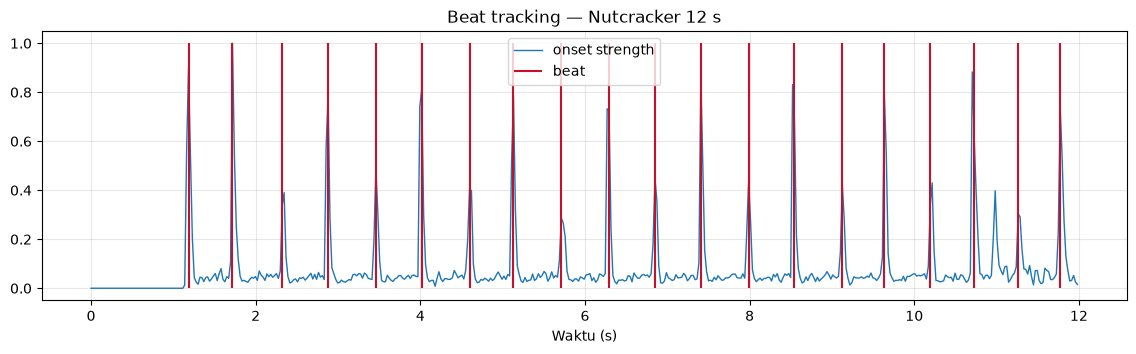

In [17]:
y12 = nutcracker[:12 * SR]
oenv_n = librosa.onset.onset_strength(y=y12, sr=SR, hop_length=HOP)
tempo_n, beats = librosa.beat.beat_track(onset_envelope=oenv_n, sr=SR, hop_length=HOP)
beat_t = librosa.frames_to_time(beats, sr=SR, hop_length=HOP)
ibi = np.diff(beat_t)

print(f"Tempo estimasi  : {float(np.atleast_1d(tempo_n)[0]):.1f} BPM")
print(f"Jumlah beat     : {len(beat_t)} dalam 12 s")
print(f"Beat pertama    : frame {beats[0]} → {beats[0]} × {HOP} / {SR} = {beat_t[0]:.3f} s")
print(f"4 beat pertama  : {np.round(beat_t[:4], 3)} → {60 / np.mean(np.diff(beat_t[:4])):.1f} BPM")
print(f"Rata-rata IBI   : {ibi.mean():.3f} s → {60 / ibi.mean():.1f} BPM (std {ibi.std() * 1000:.0f} ms)")

t_n = librosa.times_like(oenv_n, sr=SR, hop_length=HOP)
plt.figure(figsize=(14, 3.5))
plt.plot(t_n, oenv_n / oenv_n.max(), lw=1, label='onset strength')
plt.vlines(beat_t, 0, 1, color='#C8102E', label='beat')
plt.xlabel('Waktu (s)'); plt.legend(); plt.title('Beat tracking — Nutcracker 12 s')
plt.show()

# Sonifikasi: tambahkan klik di setiap beat lalu dengarkan
click = librosa.clicks(times=beat_t, sr=SR, length=len(y12))
mix = y12 + 0.5 * click
sf.write(os.path.join(OUTPUT_DIR, 'nutcracker_beats.wav'), mix, SR)
play(mix)

### 5.4 Ketika tempo berubah: tempogram

`snare_accelerate.wav` berakselerasi terus-menerus. Satu angka tempo global tidak mewakilinya. **Tempogram** menghitung autokorelasi onset envelope pada jendela yang bergeser, dan `aggregate=None` memberi **tempo lokal** per frame.

Tempo global       : 112.3 BPM
Tempo lokal awal   : 33.6 BPM
Tempo lokal akhir  : 112.3 BPM


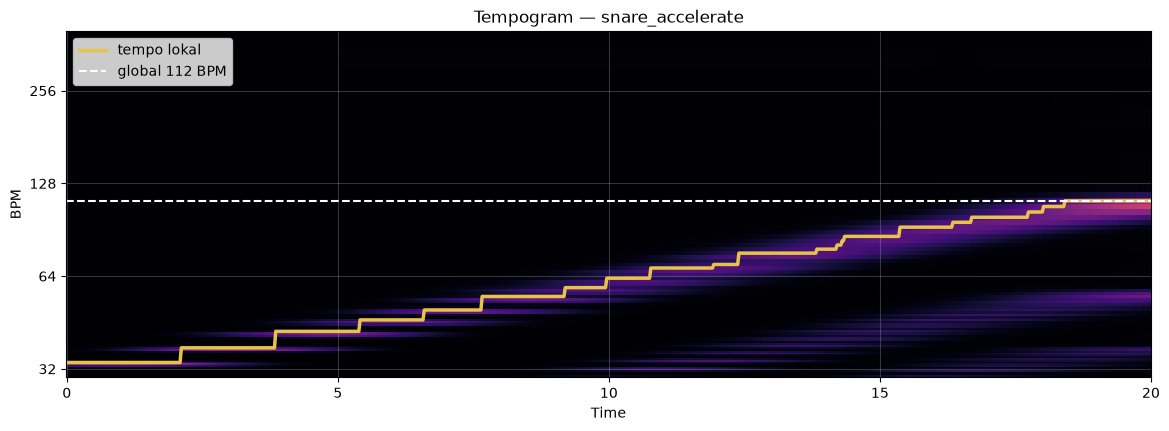

In [18]:
oenv_s = librosa.onset.onset_strength(y=snare, sr=SR, hop_length=HOP)
tg = librosa.feature.tempogram(onset_envelope=oenv_s, sr=SR, hop_length=HOP)
tempo_global = librosa.feature.tempo(onset_envelope=oenv_s, sr=SR, hop_length=HOP)[0]
tempo_local = librosa.feature.tempo(onset_envelope=oenv_s, sr=SR, hop_length=HOP, aggregate=None)
t_s = librosa.times_like(oenv_s, sr=SR, hop_length=HOP)

print(f"Tempo global       : {tempo_global:.1f} BPM")
print(f"Tempo lokal awal   : {np.median(tempo_local[:80]):.1f} BPM")
print(f"Tempo lokal akhir  : {np.median(tempo_local[-80:]):.1f} BPM")

fig, ax = plt.subplots(figsize=(14, 4.5))
librosa.display.specshow(tg, sr=SR, hop_length=HOP, x_axis='time', y_axis='tempo', ax=ax, cmap='magma')
ax.plot(t_s, tempo_local, color='#E8C34A', lw=2.5, label='tempo lokal')
ax.axhline(tempo_global, color='white', ls='--', label=f'global {tempo_global:.0f} BPM')
ax.set_ylim(30, 400); ax.legend(loc='upper left'); ax.set_title('Tempogram — snare_accelerate')
plt.show()

## 6. Chromagram & Deteksi Kunci Lagu

### 6.1 Chroma: melipat oktaf menjadi 12 kelas nada

Chromagram menjumlahkan energi semua nada dengan **kelas nada** yang sama (C3, C4, C5 → “C”). Dengan sinyal sintetis C–E–G di tiga oktaf, energi hanya muncul di tiga baris chroma.

In [19]:
def tone(midi_note, dur, sr=SR, decay=1.5, n_harm=5):
    # Nada sintetis dengan harmonik menurun (mirip piano sederhana)
    tt = np.arange(int(dur * sr)) / sr
    f = librosa.midi_to_hz(midi_note)
    s = sum((0.6 ** k) * np.sin(2 * np.pi * f * (k + 1) * tt) for k in range(n_harm))
    return s * np.minimum(1, tt / 0.01) * np.exp(-decay * tt)

seq = [48, 60, 72, 52, 64, 76, 55, 67, 79]           # C3 C4 C5 E3 E4 E5 G3 G4 G5
y_ceg = np.concatenate([tone(m, 0.6, decay=2.5) for m in seq])
y_ceg /= np.abs(y_ceg).max()

C_ceg = librosa.feature.chroma_cqt(y=y_ceg, sr=SR, hop_length=HOP)
print("Energi chroma rata-rata per kelas nada:")
for name, v in zip(NOTES, C_ceg.mean(axis=1)):
    print(f"  {name:2s} {'█' * int(v * 40)} {v:.2f}")

Energi chroma rata-rata per kelas nada:
  C  █████████████ 0.34
  C# █ 0.03
  D  ██ 0.07
  D# █ 0.04
  E  ██████████████ 0.36
  F  █ 0.03
  F# █ 0.03
  G  ███████████████ 0.40
  G# █ 0.04
  A   0.02
  A#  0.02
  B  ███ 0.08


### 6.2 Tiga varian chroma

| Fungsi | Basis | Karakter |
|---|---|---|
| `chroma_stft` | STFT (bin linear) | cepat, kurang akurat di nada rendah |
| `chroma_cqt` | Constant-Q Transform (bin log) | akurat untuk bass & musik tonal |
| `chroma_cens` | CQT + normalisasi & penghalusan | tahan dinamika/timbre — cocok untuk mencocokkan versi lagu |

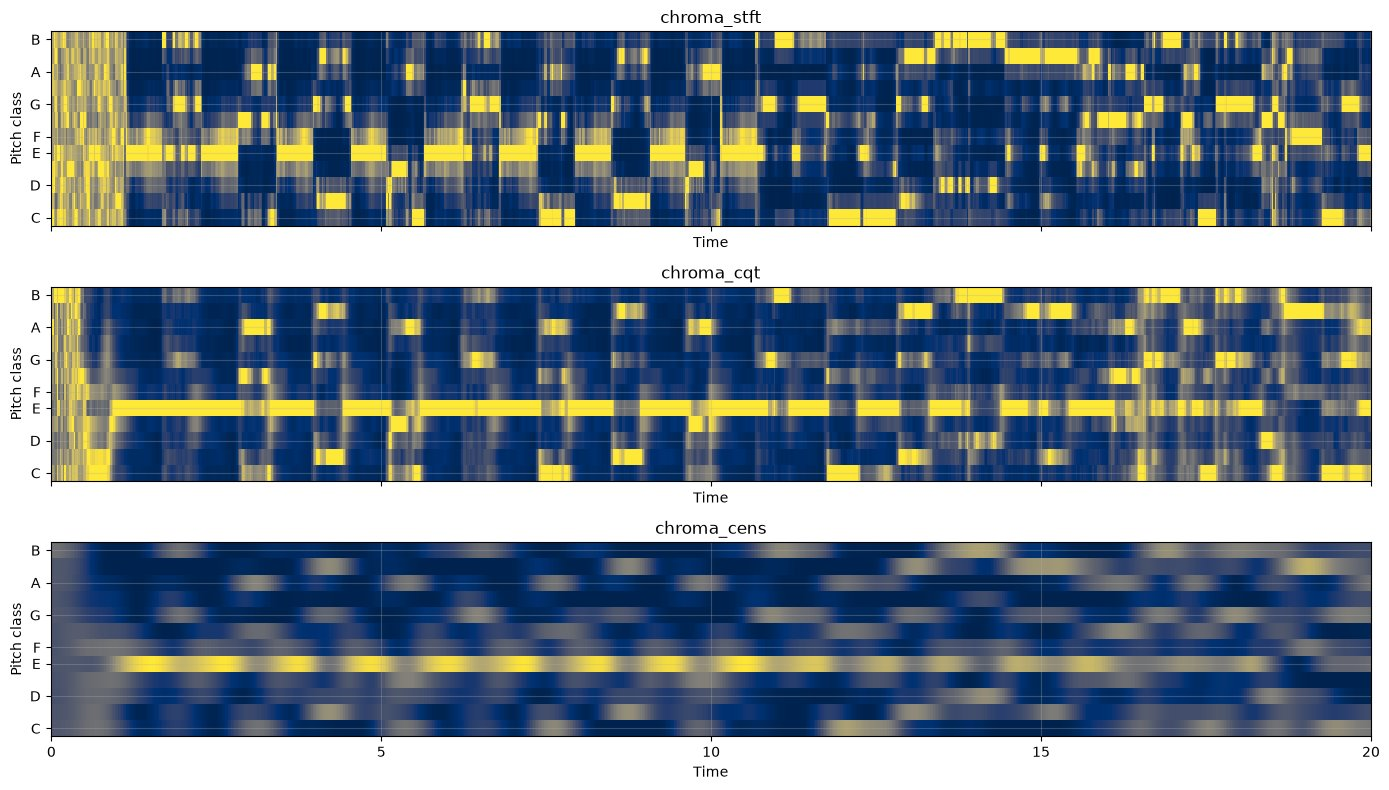

In [20]:
y20 = nutcracker[:20 * SR]
chromas = {
    'chroma_stft': librosa.feature.chroma_stft(y=y20, sr=SR, hop_length=HOP),
    'chroma_cqt':  librosa.feature.chroma_cqt(y=y20, sr=SR, hop_length=HOP),
    'chroma_cens': librosa.feature.chroma_cens(y=y20, sr=SR, hop_length=HOP),
}
fig, axs = plt.subplots(3, 1, figsize=(14, 8), sharex=True)
for ax, (name, Cm) in zip(axs, chromas.items()):
    librosa.display.specshow(Cm, sr=SR, hop_length=HOP, x_axis='time', y_axis='chroma', ax=ax, cmap='cividis')
    ax.set_title(name)
plt.tight_layout(); plt.show()

### 6.3 Algoritma Krumhansl–Schmuckler

Profil **Krumhansl–Kessler (1982)** menyatakan seberapa “cocok” tiap kelas nada dalam kunci C mayor dan C minor, berdasarkan penilaian pendengar. Untuk menebak kunci:
1. Rata-ratakan chromagram → profil 12 dimensi.
2. Putar profil C mayor/minor ke 12 tonik (`np.roll`) → **24 kandidat kunci**.
3. Hitung **korelasi Pearson** profil lagu dengan tiap kandidat.
4. Kunci = korelasi tertinggi; selisih dengan peringkat kedua menunjukkan tingkat keyakinan.

Nutcracker (30 s)        → E minor (0.774) · E mayor (0.624) · A mayor (0.390)   [selisih #1–#2: 0.150]


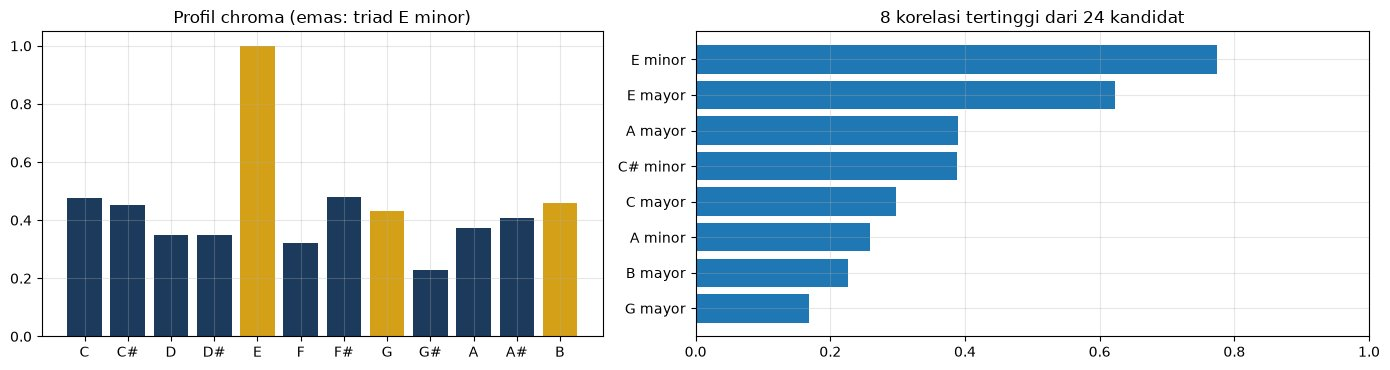

In [21]:
KK_MAJ = np.array([6.35, 2.23, 3.48, 2.33, 4.38, 4.09, 2.52, 5.19, 2.39, 3.66, 2.29, 2.88])
KK_MIN = np.array([6.33, 2.68, 3.52, 5.38, 2.60, 3.53, 2.54, 4.75, 3.98, 2.69, 3.34, 3.17])

def key_scores(profile):
    scores = []
    for i in range(12):
        scores.append((np.corrcoef(profile, np.roll(KK_MAJ, i))[0, 1], f'{NOTES[i]} mayor'))
        scores.append((np.corrcoef(profile, np.roll(KK_MIN, i))[0, 1], f'{NOTES[i]} minor'))
    return sorted(scores, reverse=True)

def estimate_key(y, top=3, verbose=True, label=''):
    profile = librosa.feature.chroma_cqt(y=y, sr=SR, hop_length=HOP).mean(axis=1)
    sc = key_scores(profile)
    if verbose:
        ranks = ' · '.join(f'{n} ({r:.3f})' for r, n in sc[:top])
        print(f'{label:24s} → {ranks}   [selisih #1–#2: {sc[0][0] - sc[1][0]:.3f}]')
    return sc[0][1], profile, sc

key_n, prof_n, sc_n = estimate_key(nutcracker, label='Nutcracker (30 s)')

fig, axs = plt.subplots(1, 2, figsize=(14, 3.8), gridspec_kw={'width_ratios': [1, 1.2]})
axs[0].bar(NOTES, prof_n / prof_n.max(), color=['#D4A017' if n in ('E', 'G', 'B') else '#1B3A5C' for n in NOTES])
axs[0].set_title('Profil chroma (emas: triad E minor)')
top8 = sc_n[:8][::-1]
axs[1].barh([n for _, n in top8], [r for r, _ in top8])
axs[1].set_title('8 korelasi tertinggi dari 24 kandidat'); axs[1].set_xlim(0, 1)
plt.tight_layout(); plt.show()

### 6.4 Menguji detektor

Sebuah detektor perlu diuji pada kasus yang jawabannya kita ketahui:
- **Progresi sintetis D–A–Bm–G** → seharusnya **D mayor** (dengan B minor, kunci relatifnya, di peringkat kedua).
- **Trumpet** dari paket *“in F”* (skala blues/Dorian) → F mayor dan F minor seharusnya bersaing ketat.
- **Transposisi:** Nutcracker yang di-*pitch shift* +2 semitone → kuncinya harus ikut bergeser dari E minor ke **F♯ minor**.

In [22]:
def chord_seq(chords, dur=1.0):
    y = np.concatenate([sum(tone(m, dur) for m in ms) for ms in chords])
    return y / np.abs(y).max() * 0.9

d_major = chord_seq([[50, 62, 66, 69], [45, 61, 64, 69], [47, 62, 66, 71], [43, 62, 67, 71]] * 2)  # D A Bm G
estimate_key(d_major, label='Sintetis D-A-Bm-G')
estimate_key(trumpet, label='Trumpet "in F"')
nut_up2 = librosa.effects.pitch_shift(nutcracker, sr=SR, n_steps=2)
estimate_key(nut_up2, label='Nutcracker +2 semitone');

Sintetis D-A-Bm-G        → D mayor (0.939) · B minor (0.794) · G mayor (0.645)   [selisih #1–#2: 0.145]
Trumpet "in F"           → F minor (0.793) · F mayor (0.775) · A# mayor (0.523)   [selisih #1–#2: 0.018]


Nutcracker +2 semitone   → F# minor (0.775) · F# mayor (0.627) · B mayor (0.356)   [selisih #1–#2: 0.148]


### 6.5 Studi kasus: label vs isi audio (Brahms)

Metadata rekaman `brahms_sample.wav` menyebut **“Hungarian Dance No. 5 in F♯ minor”**. Apa kata detektor?

In [23]:
key_b, prof_b, sc_b = estimate_key(brahms, top=5, label='Brahms (30 s)')
rank_fs = [n for _, n in sc_b].index('F# minor') + 1
print(f"F# minor berada di peringkat {rank_fs} dengan korelasi {dict((n, r) for r, n in sc_b)['F# minor']:.3f}")

# Bukti tambahan 1: penyetelan (apakah seluruh rekaman bergeser setengah nada?)
print(f"Estimasi tuning: {librosa.estimate_tuning(y=brahms, sr=SR) * 100:+.0f} cents")

# Bukti tambahan 2: nada bass yang paling sering (pYIN pada rentang 55–200 Hz)
f0_b, vf_b, _ = librosa.pyin(brahms, fmin=55, fmax=200, sr=SR, hop_length=HOP)
bass = collections.Counter(librosa.midi_to_note(np.round(librosa.hz_to_midi(f0_b[vf_b])).astype(int),
                                                octave=False, unicode=False))
print("Nada bass terbanyak:", bass.most_common(5))

Brahms (30 s)            → G minor (0.683) · G mayor (0.648) · D mayor (0.608) · D minor (0.581) · B minor (0.425)   [selisih #1–#2: 0.035]
F# minor berada di peringkat 12 dengan korelasi -0.014
Estimasi tuning: -1 cents


Nada bass terbanyak: [(np.str_('G'), 194), (np.str_('D'), 136), (np.str_('G#'), 97), (np.str_('F'), 94), (np.str_('A#'), 43)]


> 💡 **Pengamatan:** detektor memilih **G minor**, dan F♯ minor bahkan tidak masuk sepuluh besar. Tuning ~0 cents berarti rekaman tidak sekadar “turun setengah nada”, dan bass didominasi **G** dan **D** (tonik & kuint G minor). Versi piano asli Brahms memang F♯ minor, tetapi aransemen orkestra yang populer dimainkan dalam **G minor**. Label file mengikuti judul karya, bukan isi rekaman.
>
> **Pelajaran:** sebelum menyalahkan algoritma, validasi dulu *ground truth* Anda.

## 7. Chord Recognition Berbasis Template

Kunci berlaku untuk satu lagu; **chord** berubah setiap beberapa beat. Pendekatan klasik:
1. Buat 24 **template** biner 12-dimensi: triad mayor $(0, 4, 7)$ dan minor $(0, 3, 7)$ untuk 12 tonik.
2. Untuk setiap frame chroma $\mathbf{x}_m$, pilih template dengan **cosine similarity** tertinggi.

In [24]:
def chord_templates():
    T, L = [], []
    for i in range(12):
        for q, iv in (('', (0, 4, 7)), ('m', (0, 3, 7))):
            t = np.zeros(12)
            t[[(i + k) % 12 for k in iv]] = 1
            T.append(t); L.append(NOTES[i] + q)
    T = np.array(T)
    return T / np.linalg.norm(T, axis=1, keepdims=True), L

TPL, TPL_LAB = chord_templates()

def recognize(C):
    Cn = C / (np.linalg.norm(C, axis=0, keepdims=True) + 1e-9)
    return np.argmax(TPL @ Cn, axis=0)

# Uji pada progresi sintetis C - G - Am - F (×2), 1 detik per chord
prog = [('C', [48, 60, 64, 67]), ('G', [43, 59, 62, 67]), ('Am', [45, 60, 64, 69]), ('F', [41, 60, 65, 69])]
y_prog = chord_seq([ms for _, ms in prog] * 2)
C_prog = librosa.feature.chroma_cqt(y=y_prog, sr=SR, hop_length=HOP)
pred = [TPL_LAB[k] for k in recognize(C_prog)]
t_c = librosa.times_like(C_prog, sr=SR, hop_length=HOP)
truth = [prog[int(tt) % 4][0] for tt in t_c]
acc = np.mean([a == b for a, b in zip(truth, pred)])
print(f"Akurasi per frame: {acc * 100:.1f}%")
print("Prediksi di tengah tiap detik:", [pred[int((k + 0.5) * SR / HOP)] for k in range(8)])

Akurasi per frame: 96.5%
Prediksi di tengah tiap detik: ['C', 'G', 'Am', 'F', 'C', 'G', 'Am', 'F']


Pada musik nyata, melodi dan nada hias membuat label **berkedip** dari frame ke frame. Penghalusan sederhana: **median filter** pada chroma sepanjang waktu sebelum dicocokkan. Lalu kita ringkas menjadi segmen chord.

In [25]:
y15 = nutcracker[:15 * SR]
C15 = librosa.feature.chroma_cqt(y=y15, sr=SR, hop_length=HOP)
raw = recognize(C15)
smooth = recognize(ndi.median_filter(C15, size=(1, 21)))   # 21 frame ≈ 0,5 s
print(f"Pergantian label — mentah: {np.sum(raw[1:] != raw[:-1])}, setelah median filter: {np.sum(smooth[1:] != smooth[:-1])}")

def to_segments(labels, min_dur=0.4):
    segs, start = [], 0
    for i in range(1, len(labels) + 1):
        if i == len(labels) or labels[i] != labels[start]:
            dur = (i - start) * HOP / SR
            if dur >= min_dur:
                segs.append((start * HOP / SR, dur, TPL_LAB[labels[start]]))
            start = i
    return segs

print("\nSegmen chord (≥ 0,4 s) setelah penghalusan:")
for st, du, lab in to_segments(smooth):
    print(f"  {st:5.2f} s  {du:4.2f} s  {lab}")

Pergantian label — mentah: 114, setelah median filter: 69

Segmen chord (≥ 0,4 s) setelah penghalusan:
   1.72 s  0.67 s  Em
   2.86 s  0.60 s  Am
   5.09 s  0.60 s  Am
   5.71 s  0.46 s  Em
   6.20 s  1.14 s  Em
   7.38 s  0.53 s  Am
   7.99 s  0.49 s  Em
   9.10 s  0.46 s  A
   9.61 s  0.56 s  Am
  10.17 s  0.46 s  Em
  10.66 s  1.09 s  Em
  11.75 s  1.07 s  Am
  13.35 s  0.46 s  Em
  13.96 s  0.42 s  G


> 💡 **Pengamatan:** chord yang paling sering muncul adalah **Em** dan **Am** (tonik & subdominan E minor) — konsisten dengan kunci hasil Bagian 6. Sistem modern menambahkan **HMM/Viterbi** atau *deep learning*, kosakata chord yang lebih luas (7, sus, inversi), dan sinkronisasi dengan beat.

## 8. Audio Fingerprinting: Mini-Shazam

Ide Avery Wang (2003), pendiri teknologi Shazam:
1. **Constellation map** — simpan hanya **puncak lokal** spektrogram; titik terkuat hampir selalu selamat dari noise.
2. **Combinatorial hashing** — pasangkan setiap *anchor* dengan beberapa puncak di **target zone** di depannya menjadi hash $(f_1, f_2, \Delta t)$.
3. **Indeks** — tabel `hash → [(lagu, t_anchor)]`.
4. **Voting offset** — hash yang benar menghasilkan selisih waktu $t_\text{db} - t_\text{query}$ yang **sama**.

In [26]:
def fp_peaks(y, size=20, floor_db=-50):
    D = spec_db(y)
    mx = ndi.maximum_filter(D, size=(size, size))
    pk = np.argwhere((D == mx) & (D > floor_db))          # (bin_frekuensi, frame)
    return D, pk[np.lexsort((pk[:, 0], pk[:, 1]))]       # urutkan berdasarkan waktu

def fp_hashes(pk, fan=10, dt_min=3, dt_max=40, df_max=100):
    # Pasangkan setiap anchor dengan <= fan puncak di target zone persegi di depannya
    hs = []
    for i, (f1, t1) in enumerate(pk):
        n = 0
        for f2, t2 in pk[i + 1:]:
            dt = t2 - t1
            if dt > dt_max or n >= fan:
                break
            if dt >= dt_min and abs(int(f2) - int(f1)) <= df_max:
                hs.append(((int(f1), int(f2), int(dt)), int(t1)))
                n += 1
    return hs

SONGS = {'Nutcracker': nutcracker, 'Brahms': brahms, 'Vibe Ace': music, 'Trumpet': trumpet, 'Drums': drums}
DB = {}
t0 = time.perf_counter()
for name, y in SONGS.items():
    hs = fp_hashes(fp_peaks(y)[1])
    for h, t in hs:
        DB.setdefault(h, []).append((name, t))
    print(f"{name:11s} {len(y)/SR:5.1f} s → {len(hs):6d} hash")
print(f"Indeks: {len(DB)} hash unik, {sum(len(v) for v in DB.values())} entri, dibangun dalam {time.perf_counter() - t0:.2f} s")

Nutcracker   30.0 s →   6642 hash


Brahms       30.0 s →  13054 hash


Vibe Ace     10.0 s →   3704 hash
Trumpet       5.3 s →   1043 hash
Drums         8.0 s →   4879 hash


Indeks: 28007 hash unik, 29322 entri, dibangun dalam 0.26 s


Query 3 s: 155 puncak, 1178 hash


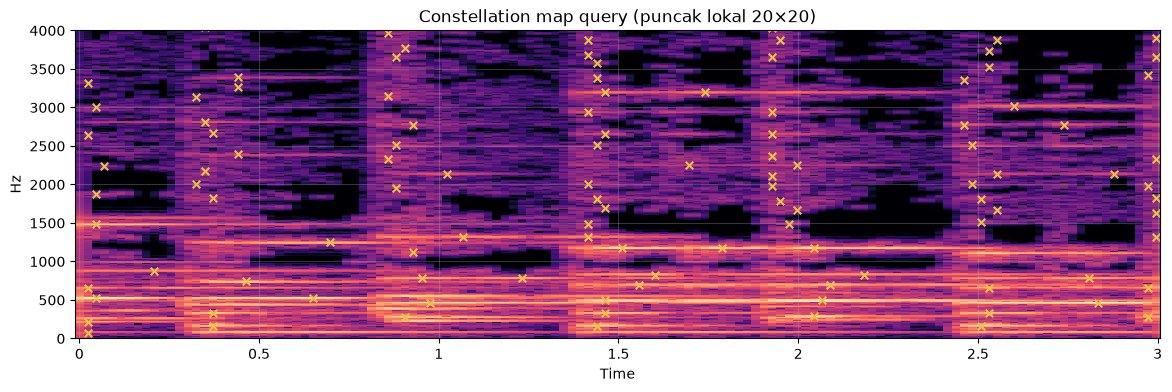

In [27]:
Q_START, Q_DUR = 12.0, 3.0
query = nutcracker[int(Q_START * SR):int((Q_START + Q_DUR) * SR)]

D_q, pk_q = fp_peaks(query)
print(f"Query 3 s: {len(pk_q)} puncak, {len(fp_hashes(pk_q))} hash")

fig, ax = plt.subplots(figsize=(14, 4))
librosa.display.specshow(D_q, sr=SR, hop_length=HOP, x_axis='time', y_axis='linear', ax=ax, cmap='magma')
ax.scatter(pk_q[:, 1] * HOP / SR, pk_q[:, 0] * SR / 2048, marker='x', color='#E8C34A', s=30)
ax.set_ylim(0, 4000); ax.set_title('Constellation map query (puncak lokal 20×20)')
plt.show()

Query + noise 0 dB (noise sekeras musik):
→ Nutcracker pada detik 12.00 (skor 64)


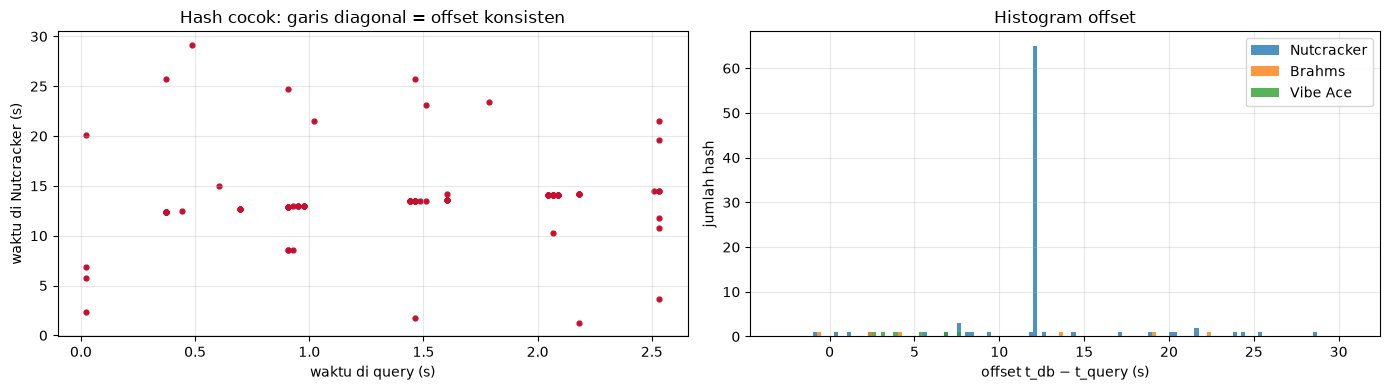

In [28]:
def add_noise(y, snr_db, seed=0):
    rng = np.random.default_rng(seed)
    noise = rng.standard_normal(len(y))
    noise *= np.sqrt(np.mean(y ** 2) / 10 ** (snr_db / 10)) / np.std(noise)
    return y + noise

def identify(q, verbose=True):
    votes = collections.Counter()
    pairs = collections.defaultdict(list)
    for h, t_q in fp_hashes(fp_peaks(q)[1]):
        for name, t_db in DB.get(h, []):
            votes[(name, t_db - t_q)] += 1
            pairs[name].append((t_q, t_db))
    (name, off), score = votes.most_common(1)[0]
    if verbose:
        print(f"→ {name} pada detik {off * HOP / SR:.2f} (skor {score})")
    return name, off, score, votes, pairs

q0 = add_noise(query, 0)
print("Query + noise 0 dB (noise sekeras musik):")
name, off, score, votes, pairs = identify(q0)
ipd.display(play(q0))

fig, axs = plt.subplots(1, 2, figsize=(14, 4))
pl = np.array(pairs['Nutcracker'])
axs[0].scatter(pl[:, 0] * HOP / SR, pl[:, 1] * HOP / SR, s=12, color='#C8102E')
axs[0].set_xlabel('waktu di query (s)'); axs[0].set_ylabel('waktu di Nutcracker (s)')
axs[0].set_title('Hash cocok: garis diagonal = offset konsisten')
for n_ in ('Nutcracker', 'Brahms', 'Vibe Ace'):
    offs = [td - tq for tq, td in pairs.get(n_, [])]
    if offs:
        axs[1].hist(np.array(offs) * HOP / SR, bins=np.arange(-3, 31, 0.25), alpha=0.8, label=n_)
axs[1].set_xlabel('offset t_db − t_query (s)'); axs[1].set_ylabel('jumlah hash')
axs[1].set_title('Histogram offset'); axs[1].legend()
plt.tight_layout(); plt.show()

### 8.1 Seberapa tangguh?

Kita uji query yang sama pada enam kondisi dan bandingkan skor lagu yang benar dengan skor terbaik lagu lain. Sebuah hasil kita anggap **dikenali** bila skornya minimal 10 hash dan minimal 3× skor lagu lain.

In [29]:
conditions = {
    'Bersih': query,
    'Noise 10 dB': add_noise(query, 10),
    'Noise 0 dB': add_noise(query, 0),
    'Noise -5 dB': add_noise(query, -5),
    'Stretch 1,1×': librosa.effects.time_stretch(query, rate=1.1),
    'Pitch +1 semitone': librosa.effects.pitch_shift(query, sr=SR, n_steps=1),
}
print(f"{'kondisi':18s} {'benar':>6s} {'lain':>5s}  hasil")
for cname, q in conditions.items():
    _, _, _, votes, _ = identify(q, verbose=False)
    true_v = max([v for (s, o), v in votes.items() if s == 'Nutcracker'] or [0])
    other_v = max([v for (s, o), v in votes.items() if s != 'Nutcracker'] or [0])
    verdict = 'dikenali' if (true_v >= 10 and true_v >= 3 * max(other_v, 1)) else 'meragukan'
    print(f"{cname:18s} {true_v:6d} {other_v:5d}  {verdict}")

kondisi             benar  lain  hasil
Bersih                376     2  dikenali
Noise 10 dB            89     1  dikenali
Noise 0 dB             64     1  dikenali
Noise -5 dB            59     1  dikenali
Stretch 1,1×           11     2  dikenali
Pitch +1 semitone       4     1  meragukan


> 💡 **Pengamatan:** noise hingga **−5 dB** (noise lebih keras dari musik) masih dikenali dengan jelas, karena puncak spektrum terkuat tetap bertahan. Time stretch 10 % menurunkan skor tetapi masih menang. Namun **pitch shift 1 semitone** meruntuhkan skor: hash menyimpan **frekuensi absolut** $f_1, f_2$ yang ikut bergeser. Sistem komersial menambahkan trik tambahan (mis. hash berbasis rasio frekuensi) untuk kasus seperti ini.

## 9. Rangkuman: Profil Musikal Satu Lagu

Sebagai penutup, kita gabungkan semua teknik menjadi satu fungsi “laporan” untuk sebuah berkas audio. Ganti `path` dengan lagu Anda sendiri (WAV/MP3, 15–30 detik) untuk mencobanya.

In [30]:
def music_profile(path, duration=30):
    y, sr = librosa.load(path, sr=SR, duration=duration)
    oenv = librosa.onset.onset_strength(y=y, sr=sr, hop_length=HOP)
    tempo, beats = librosa.beat.beat_track(onset_envelope=oenv, sr=sr, hop_length=HOP)
    key, _, sc = estimate_key(y, verbose=False)
    f0, vf, _ = librosa.pyin(y, sr=sr, fmin=200, fmax=2000, hop_length=HOP)
    C = ndi.median_filter(librosa.feature.chroma_cqt(y=y, sr=sr, hop_length=HOP), size=(1, 21))
    chords = collections.Counter(TPL_LAB[k] for k in recognize(C)).most_common(4)
    print(f"Berkas       : {path} ({len(y)/sr:.1f} s)")
    print(f"Tempo        : {float(np.atleast_1d(tempo)[0]):.1f} BPM ({len(beats)} beat)")
    print(f"Kunci        : {key}  (kandidat #2: {sc[1][1]}, selisih {sc[0][0] - sc[1][0]:.3f})")
    if vf.any():
        print(f"Melodi       : median {librosa.hz_to_note(np.nanmedian(f0))}, {vf.mean() * 100:.0f}% frame bersuara")
    print(f"Chord teratas: {', '.join(c for c, _ in chords)}")

music_profile(os.path.join(AUDIO_DIR, 'nutcracker_sample.wav'))

Berkas       : audio/nutcracker_sample.wav (30.0 s)
Tempo        : 112.3 BPM (47 beat)
Kunci        : E minor  (kandidat #2: E mayor, selisih 0.150)
Melodi       : median B3, 69% frame bersuara
Chord teratas: Em, Am, F#, A


### 📚 Ringkasan Konsep

1. **Nada** berskala log: $m = 69 + 12\log_2(f/440)$; 1 semitone = ×1,0595; 1 oktaf = ×2. *Pitch* ditentukan oleh periodisitas ($f_0$), bukan harmonik terkuat.
2. **Resample** mengubah durasi *dan* pitch; **time stretch** (phase vocoder) hanya durasi; **pitch shift** = stretch + resample. Waspadai *transient smearing* dan pergeseran **formant**.
3. **Deteksi pitch:** ACF → YIN (ambil τ *pertama* di bawah ambang) → pYIN (multi-ambang + HMM). Musuh utamanya adalah **octave error**.
4. **Ritme:** onset dari **spectral flux**, tempo dari **autokorelasi** onset envelope (ambigu ×2/½, dipengaruhi prior), beat dari **dynamic programming**; gunakan **tempogram** bila tempo berubah.
5. **Kunci lagu:** rata-rata **chroma** dikorelasikan dengan 24 profil **Krumhansl–Kessler**; pasangan relatif (C mayor/A minor) paling mudah tertukar.
6. **Chord:** cosine similarity chroma dengan **template triad**, lalu dihaluskan.
7. **Fingerprinting:** puncak spektrogram → hash $(f_1, f_2, \Delta t)$ → **voting offset**. Tahan noise, tetapi rentan terhadap pitch shift.

### ✅ Lima Kebiasaan Baik
| # | Kebiasaan |
|---|---|
| 1 | Samakan `sr` di seluruh analisis (di sini 22050 Hz) |
| 2 | Selalu sadari satuan: **frame**, **sampel**, atau **detik** (`frames_to_time`) |
| 3 | Batasi `fmin`/`fmax` sesuai instrumen |
| 4 | Laporkan juga **kandidat kedua** (68 vs 136 BPM, mayor vs relatif) |
| 5 | **Dengarkan** hasilnya — klik beat, audio hasil shift — sebelum memercayai angka |

---
*Selamat! Modul audio telah selesai. Pada pertemuan berikutnya kita beralih ke **citra digital**: representasi citra sebagai array `(H, W, C)`, bit depth, ruang warna, dan histogram.*